#### Libraries

In [4]:
import numpy as np
import pandas as pd
import gurobipy as gp
from gurobipy import GRB
from scipy.stats import norm

#### Parameters

In [5]:
alpha = 0.95
k = norm.pdf(norm.ppf(alpha)) / (1 - alpha)
print(k) 

2.0627128075074275


#### Sets

In [6]:
df = pd.read_csv("selected_monthly_return.csv", encoding="utf-8-sig")
tickers = df["Ticker"].tolist()
returns = df.drop(columns=["PERMNO", "Ticker", "average_monthly_return"])
mu = df["average_monthly_return"].to_numpy(dtype=float)

#### Covariance Matrix

In [7]:
cov_df = pd.read_csv("covariance_matrix.csv", skiprows=1, encoding="utf-8-sig")

Sigma = cov_df.drop(columns=["PERMNO", "Ticker"]).to_numpy(dtype=float)

eigvals, eigvecs = np.linalg.eigh(Sigma)
A = np.sqrt(np.clip(eigvals, 0, None))[:, None] * eigvecs.T

In [8]:
# Identify stock pairs with correlation above 0.8

rho_threshold = 0.80

std = np.sqrt(np.diag(Sigma))
corr_matrix = Sigma / np.outer(std, std)

conflicting_pairs = []

for i in range(len(tickers)):
    for j in range(i + 1, len(tickers)):
        if corr_matrix[i, j] > rho_threshold:
            conflicting_pairs.append((i, j))

print("Number of conflicting pairs:", len(conflicting_pairs))

for i, j in conflicting_pairs:
    print(f"{tickers[i]:<5} {tickers[j]:<5}",
          f"Correlation: {corr_matrix[i, j]:.4f}")

Number of conflicting pairs: 8
NEM   B     Correlation: 0.8273
NEM   AEM   Correlation: 0.8058
KLAC  LRCX  Correlation: 0.8477
LRCX  MU    Correlation: 0.8206
B     AEM   Correlation: 0.8006
B     WPM   Correlation: 0.8137
AEM   KGC   Correlation: 0.8361
AEM   WPM   Correlation: 0.8486


### Model

$$
\begin{aligned}
\min_{w,z}\quad
&-\sum_{i\in I}\hat{\mu}_i^M w_i
+k_\alpha\|Aw\|_2 \\[6pt]
\text{s.t.}\quad
&\sum_{i\in I}w_i=1,\\[4pt]
&0.01z_i\leq w_i\leq0.20z_i,
&&\forall i\in I,\\[4pt]
&z_i+z_j\leq1,
&&\forall(i,j)\in P,\\[4pt]
&\sum_{i\in I}\hat{\mu}_i^M w_i\geq b,\\[4pt]
&z_i\in\{0,1\},
&&\forall i\in I.
\end{aligned}
$$

In [9]:
# model
m = gp.Model("portfolio")

Set parameter Username
Set parameter LicenseID to value 2871492
Academic license - for non-commercial use only - expires 2027-10-05


#### Decision Variables

In [10]:
# weights
w = m.addMVar(len(tickers), vtype=GRB.CONTINUOUS, name="w")
# indicator variable for investing in a specific stock
z = m.addMVar(len(tickers), vtype=GRB.BINARY, name="z")
# standard deviation of portfolio (helper variable)
s = m.addVar(vtype=GRB.CONTINUOUS, name="s")

#### Constraints

In [11]:
# full investment of capital
m.addConstr(w.sum() == 1, name="full_investment")
# min and max weight
m.addConstr(w <= 0.2 * z, name="max_investment")
m.addConstr(0.01 * z <= w, name = "min_investment")
# correlation restriction
for i, j in conflicting_pairs:
    m.addConstr(
        z[i] + z[j] <= 1,
        name=f"correlation_{i}_{j}"
    )

In [12]:
# average returns at least as good as s&p
benchmark = pd.read_csv("SP500_monthly_202001_202603.csv", encoding="utf-8-sig")
benchmark["Month"] = pd.to_datetime(benchmark["Month"])
b = benchmark.loc[benchmark["Month"].between("2021-01-01", "2025-12-31"), "MonthlyReturn"].mean()
m.addConstr(w @ mu >= b, name="minimum_return")

<MConstr () *awaiting model update*>

In [13]:
# helper constraint for the standard deviation to be added to objective function
y = m.addMVar(len(tickers), lb=-GRB.INFINITY, name="y") # helper variable for finding s 
m.addConstr(y == A @ w)
m.addGenConstrNorm(s, y, 2.0) # constraint to find s

<gurobi.GenConstr *Awaiting Model Update*>

#### Objective Function

In [14]:
m.setObjective(-1 * w @ mu + k * s, gp.GRB.MINIMIZE)

#### Results

In [15]:
m.optimize()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 27.0.0 26A434)

CPU model: Apple M1
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 121 rows, 112 columns and 1644 nonzeros (Min)
Model fingerprint: 0xf280d0f0
Model has 38 linear objective coefficients
Model has 1 simple general constraint
  1 NORM
Variable types: 75 continuous, 37 integer (37 binary)
Coefficient statistics:
  Matrix range     [1e-06, 1e+00]
  Objective range  [2e-03, 2e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e-02, 1e+00]

Presolve removed 3 rows and 0 columns
Presolve time: 0.01s
Presolved: 119 rows, 149 columns, 1672 nonzeros
Presolved model has 37 quadratic constraint(s)
Variable types: 112 continuous, 37 integer (37 binary)

Root relaxation: objective -3.969804e-02, 43 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumb

In [16]:
portfolio = pd.DataFrame({"Ticker": tickers, "Optimized Weight": w.X})
print(portfolio.to_string(index=False, formatters={"Optimized Weight": "{:.3%}".format}))

Ticker Optimized Weight
  COHR           0.000%
    GE           0.000%
   FNV           0.000%
    UI           0.000%
  BABA           3.801%
  LITE           0.000%
  CVNA           0.000%
   CVS           6.812%
   NET           0.000%
  PLTR           0.000%
  SOFI           0.000%
   NEM           0.000%
   CAH          19.981%
   GLW           0.000%
   HWM           0.000%
  KLAC           0.000%
  LRCX           0.000%
    MU           0.000%
  INTC           0.000%
   AMD           0.000%
   WDC           0.000%
     B           0.000%
  IDXX           0.000%
   AEM           0.000%
  ESLT          20.000%
  CIEN           0.000%
   APH           0.000%
   FIX           7.819%
    MT           0.000%
   CLS           0.000%
  INSM           4.157%
    DB           8.114%
   STX           0.000%
   KGC           0.000%
   NRG           0.000%
   WPM          14.054%
  AVGO          15.262%


In [17]:
portfolio_return = mu @ w.X

print(f"Portfolio returns: {portfolio_return:.6%}")
print(f"Portfolio monthly standard deviation: {s.X:.6%}")
print(f"Portfolio monthly 95% CVaR: {m.ObjVal:.6%}")

Portfolio returns: 3.004309%
Portfolio monthly standard deviation: 4.331404%
Portfolio monthly 95% CVaR: 5.930133%


In [18]:
print(f"Historical benchmark mean monthly return b: {b:.6%}") # 2021-2025
print(f"Excess return: {(portfolio_return - b):.6%}")

Historical benchmark mean monthly return b: 1.099027%
Excess return: 1.905282%


### Actual Portfolio Return vs. Actual S&P 500 Return in Jan 2026

In [19]:
# Out-of-sample evaluation: January 2026
sp500_jan = benchmark.loc[
    benchmark["Month"] == "2026-01",
    "MonthlyReturn"
].iloc[0]

actual_jan_return = df["26-Jan"] @ w.X

actual_excess_return = actual_jan_return - sp500_jan

print(f"Actual portfolio return in January 2026: {actual_jan_return:.6%}")
print(f"Actual S&P 500 return in January 2026: {sp500_jan:.6%}")
print(f"Actual excess return in January 2026: {actual_excess_return:.6%}")

Actual portfolio return in January 2026: 8.060061%
Actual S&P 500 return in January 2026: 1.366446%
Actual excess return in January 2026: 6.693616%


### Out-of-Sample Evaluation: January–March 2026

In [20]:
# Buy-and-hold portfolio without rebalancing

months = ["2026-01", "2026-02", "2026-03"]
stock_cols = ["26-Jan", "26-Feb", "26-Mar"]

# Actual monthly returns of the 37 stocks
stock_returns = df[stock_cols].to_numpy(dtype=float)

# Actual S&P 500 monthly returns
sp500_returns = (
    benchmark.set_index(benchmark["Month"].dt.strftime("%Y-%m"))
    .loc[months, "MonthlyReturn"]
    .to_numpy(dtype=float)
)

# Value of each stock position over time
weights = w.X.copy()
portfolio_monthly_returns = stock_returns.T @ weights 
portfolio_cumulative_returns = np.cumprod(1 + portfolio_monthly_returns) - 1

# S&P 500 cumulative returns
sp500_cumulative_returns = (
    np.cumprod(1 + sp500_returns) - 1
)

# Summary table
comparison = pd.DataFrame({
    "Month": months,
    "Portfolio Monthly Return": portfolio_monthly_returns,
    "S&P 500 Monthly Return": sp500_returns,
    "Portfolio Cumulative Return": portfolio_cumulative_returns,
    "S&P 500 Cumulative Return": sp500_cumulative_returns
})

print(comparison.to_string(
    index=False,
    formatters={
        col: "{:.4%}".format
        for col in comparison.columns if col != "Month"
    }
))

print("\nThree-month cumulative results:")
print(f"Portfolio: {portfolio_cumulative_returns[-1]:.4%}")
print(f"S&P 500: {sp500_cumulative_returns[-1]:.4%}")
print(
    f"Excess cumulative return: "
    f"{portfolio_cumulative_returns[-1] - sp500_cumulative_returns[-1]:.4%}"
)

  Month Portfolio Monthly Return S&P 500 Monthly Return Portfolio Cumulative Return S&P 500 Cumulative Return
2026-01                  8.0601%                1.3664%                     8.0601%                   1.3664%
2026-02                  6.9741%               -0.8669%                    15.5963%                   0.4877%
2026-03                 -5.0657%               -5.0936%                     9.7406%                  -4.6307%

Three-month cumulative results:
Portfolio: 9.7406%
S&P 500: -4.6307%
Excess cumulative return: 14.3713%


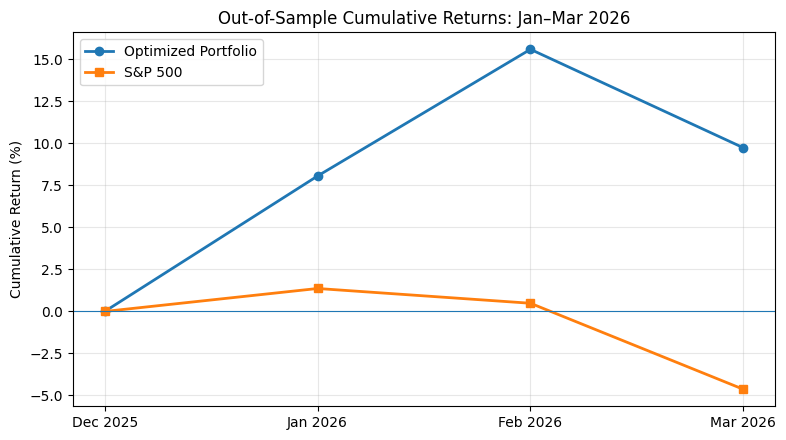

In [21]:
import matplotlib.pyplot as plt

plot_months = ["Dec 2025", "Jan 2026", "Feb 2026", "Mar 2026"]

portfolio_cum = [0] + portfolio_cumulative_returns.tolist()
sp500_cum = [0] + sp500_cumulative_returns.tolist()

plt.figure(figsize=(8, 4.5))

plt.plot(
    plot_months,
    np.array(portfolio_cum) * 100,
    marker="o",
    linewidth=2,
    label="Optimized Portfolio"
)

plt.plot(
    plot_months,
    np.array(sp500_cum) * 100,
    marker="s",
    linewidth=2,
    label="S&P 500"
)

plt.axhline(0, linewidth=0.8)
plt.ylabel("Cumulative Return (%)")
plt.title("Out-of-Sample Cumulative Returns: Jan–Mar 2026")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# saving figure
plt.savefig("performance_comparison.png", dpi=300)
plt.show()

### Sanity Checks

In [22]:
# Verify the optimized portfolio independently
weights = np.array(w.X)
selected = np.array(z.X)
tol = 1e-5

# 1. Full investment
print("Sum of weights:", weights.sum())
print("Full investment:",
      abs(weights.sum() - 1) <= tol)

# 2. Minimum and maximum stock weights
print("Minimum investment:",
      np.all(weights >= 0.01 * selected - tol))
print("Maximum investment:",
      np.all(weights <= 0.20 * selected + tol))

# 3. Minimum expected return
expected_return = mu @ weights
print("Return requirement:",
      expected_return >= b - tol)

# 4. Correlation restriction
violations = [
    (tickers[i], tickers[j])
    for i, j in conflicting_pairs
    if selected[i] + selected[j] > 1 + tol
]

print("Correlation violations:", violations)

# 5. Independently calculate standard deviation and CVaR
calculated_std = np.linalg.norm(A @ weights)
calculated_cvar = -expected_return + k * calculated_std

print(f"Calculated standard deviation: {calculated_std:.6%}")
print(f"Calculated CVaR: {calculated_cvar:.6%}")
print(f"Gurobi CVaR: {m.ObjVal:.6%}")
print(f"CVaR difference: {abs(calculated_cvar - m.ObjVal):.10f}")
print(f"Maximum constraint violation: {m.ConstrVio:.10f}")

Sum of weights: 1.0000000580769444
Full investment: True
Minimum investment: True
Maximum investment: True
Return requirement: True
Correlation violations: []
Calculated standard deviation: 4.331404%
Calculated CVaR: 5.930134%
Gurobi CVaR: 5.930133%
CVaR difference: 0.0000000050
Maximum constraint violation: 0.0000000581


### Milestone 5 — Sensitivity Analysis

We vary one policy parameter at a time and re-optimize, holding all other inputs and constraints fixed. The baseline is a correlation threshold of 0.80 and a maximum individual weight of 20%. We check feasibility, objective consistency, and whether the portfolio allocation changes. All out-of-sample returns use the **same January–March 2026 buy-and-hold** evaluation window.

In [23]:
# Reusable sensitivity solver — keeps the original baseline model unchanged
# Requires cells above (through the buy-and-hold evaluation) to have been run.

def solve_policy(correlation_threshold=0.80, weight_cap=0.20):
    n = len(tickers)
    pairs = [(i, j) for i in range(n) for j in range(i + 1, n)
             if corr_matrix[i, j] > correlation_threshold]

    sm = gp.Model(f"rho_{correlation_threshold:.2f}_cap_{weight_cap:.2f}")
    # to remove print outputs when model optimizes
    sm.setParam("OutputFlag", 0)
    sw = sm.addMVar(n, lb=0.0, name="weights")
    sz = sm.addMVar(n, vtype=GRB.BINARY, name="selected")
    sy = sm.addMVar(n, lb=-GRB.INFINITY, name="y")
    ss = sm.addVar(lb=0.0, name="std")

    sm.addConstr(sw.sum() == 1, name="full_investment")
    sm.addConstr(sw >= 0.01 * sz, name="min_weight")
    sm.addConstr(sw <= weight_cap * sz, name="max_weight")
    sm.addConstr(sw @ mu >= b, name="benchmark_return")
    for i, j in pairs:
        sm.addConstr(sz[i] + sz[j] <= 1,
                     name=f"correlation_{i}_{j}")
    sm.addConstr(sy == 100 * (A @ sw), name="covariance_factor")  # Scale the norm by 100 to improve numerical accuracy
    sm.addGenConstrNorm(ss, sy, 2.0, name="portfolio_std")
    sm.setObjective(-(sw @ mu) + k * ss / 100, GRB.MINIMIZE)
    sm.optimize()

    row = {"Correlation Threshold": correlation_threshold,
           "Max Weight Cap": weight_cap,
           "Status": sm.Status,
           "Conflicting Pairs": len(pairs)}
    if sm.Status != GRB.OPTIMAL:
        print(f"Not optimal: rho={correlation_threshold:.2f}, "
              f"cap={weight_cap:.0%}, status={sm.Status}")
        return row, None

    ww = np.asarray(sw.X, dtype=float)
    zz = np.asarray(sz.X, dtype=float)
    expected = float(mu @ ww)
    sigma = float(np.linalg.norm(A @ ww))
    cvar = -expected + k * sigma
    objective = float(sm.ObjVal)
    oos = float(np.dot(ww, np.prod(1 + stock_returns, axis=1)) - 1)

    row.update({
        "Selected Stocks": int(np.sum(zz > 0.5)),
        "Expected Return": expected,
        "Std Dev": sigma,
        "CVaR": cvar,
        "OOS Return": oos,
        "Largest Weight": float(ww.max()),
        "HHI": float(np.sum(ww ** 2)),
        "Portfolio Rate of Return": abs(cvar - objective),
        "Solver MIP Gap": float(sm.MIPGap),
        "Weight L1 Difference vs Baseline": float(np.sum(np.abs(ww - np.asarray(w.X)))),
    })
    return row, ww

#### A. Correlation Threshold Sensitivity

Vary ρ from 0.60 to 0.95 while holding the individual stock weight cap fixed at 20%. Lower thresholds impose more exclusions. Compare risk, return, composition, and realized hold-period performance.

In [24]:
thresholds = [0.60, 0.70, 0.80, 0.90, 0.95]
correlation_rows, correlation_weights = [], {}
for rho in thresholds:
    result, new_weights = solve_policy(correlation_threshold=rho, weight_cap=0.20)
    correlation_rows.append(result)
    correlation_weights[rho] = new_weights

correlation_df = pd.DataFrame(correlation_rows)
display(correlation_df)
correlation_df.to_csv("correlation_sensitivity.csv", index=False)

valid_corr = correlation_df.dropna(subset=["CVaR"])

# Compare the re-solved 0.80 portfolio against the original baseline.
print("Baseline 0.80 CVaR difference:",
      abs(float(valid_corr.loc[valid_corr["Correlation Threshold"] == 0.80, "CVaR"].iloc[0]) - m.ObjVal))
print("Baseline 0.80 weight L1 difference:",
      np.sum(np.abs(correlation_weights[0.80] - np.asarray(w.X))))

,Correlation Threshold,Max Weight Cap,Status,Conflicting Pairs,Selected Stocks,Expected Return,Std Dev,CVaR,OOS Return,Largest Weight,HHI,Portfolio Rate of Return,Solver MIP Gap,Weight L1 Difference vs Baseline
0,0.60,0.2,2,37,9,0.030044,0.043314,0.059301,0.105532,0.2,0.143563,7.557843e-14,0.000098,0.000802
1,0.70,0.2,2,19,9,0.030044,0.043314,0.059301,0.105532,0.2,0.143563,7.557843e-14,0.000053,0.000802
2,0.80,0.2,2,8,9,0.030044,0.043314,0.059301,0.105532,0.2,0.143563,7.557843e-14,0.000098,0.000802
3,0.90,0.2,2,0,10,0.029903,0.043247,0.059303,0.110490,0.2,0.141647,1.718903e-13,0.000071,0.020001
4,0.95,0.2,2,0,10,0.029903,0.043247,0.059303,0.110490,0.2,0.141647,1.718903e-13,0.000071,0.020001


Baseline 0.80 CVaR difference: 6.49304358543712e-08
Baseline 0.80 weight L1 difference: 0.0008021919246802914


#### B. Maximum Individual Weight Cap Sensitivity

Vary the weight cap from 10% to 30% while holding the correlation threshold fixed at 0.80. Keep the 1% conditional minimum weight and all other model inputs unchanged.

In [25]:
caps = [0.10, 0.15, 0.20, 0.25, 0.30]
cap_rows, cap_weights = [], {}
for cap in caps:
    result, new_weights = solve_policy(correlation_threshold=0.80, weight_cap=cap)
    cap_rows.append(result)
    cap_weights[cap] = new_weights

cap_df = pd.DataFrame(cap_rows)
display(cap_df)
cap_df.to_csv("weight_cap_sensitivity.csv", index=False)

valid_cap = cap_df.dropna(subset=["CVaR"])
print("Baseline 20% cap CVaR difference:",
      abs(float(valid_cap.loc[valid_cap["Max Weight Cap"] == 0.20, "CVaR"].iloc[0]) - m.ObjVal))
print("Baseline 20% cap weight L1 difference:",
      np.sum(np.abs(cap_weights[0.20] - np.asarray(w.X))))

,Correlation Threshold,Max Weight Cap,Status,Conflicting Pairs,Selected Stocks,Expected Return,Std Dev,CVaR,OOS Return,Largest Weight,HHI,Portfolio Rate of Return,Solver MIP Gap,Weight L1 Difference vs Baseline
0,0.8,0.10,2,8,15,0.027830,0.045195,0.065394,0.082515,0.100000,0.086993,1.370130e-11,0.000094,0.609510
1,0.8,0.15,2,8,11,0.029362,0.043628,0.060630,0.106259,0.150000,0.120406,1.522948e-12,0.000048,0.219586
2,0.8,0.20,2,8,9,0.030044,0.043314,0.059301,0.105532,0.200000,0.143563,7.557843e-14,0.000098,0.000802
3,0.8,0.25,2,8,9,0.030065,0.043321,0.059293,0.108128,0.206215,0.144638,1.579570e-13,0.000026,0.013085
4,0.8,0.30,2,8,9,0.030064,0.043320,0.059293,0.108161,0.206176,0.144635,6.144391e-14,0.000054,0.013078


Baseline 20% cap CVaR difference: 6.49304358543712e-08
Baseline 20% cap weight L1 difference: 0.0008021919246802914


#### Sensitivity Figures

The plots show optimized 95% monthly CVaR versus the varied policy parameter. Review results and solver checks before drawing investment recommendations.

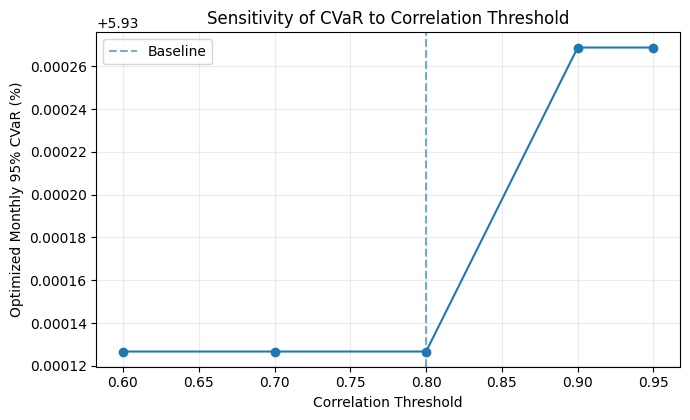

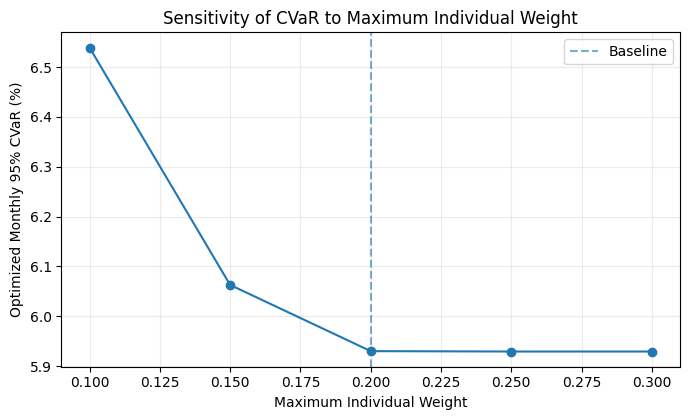

In [26]:
import matplotlib.pyplot as plt

for data, xcol, xlabel, filename, baseline in [
    (correlation_df, "Correlation Threshold", "Correlation Threshold", "correlation_sensitivity.png", 0.80),
    (cap_df, "Max Weight Cap", "Maximum Individual Weight", "weight_cap_sensitivity.png", 0.20),
]:
    fig, ax = plt.subplots(figsize=(7, 4.3))
    valid = data.dropna(subset=["CVaR"])
    ax.plot(valid[xcol], 100 * valid["CVaR"], marker="o")
    ax.axvline(baseline, linestyle="--", alpha=0.6, label="Baseline")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Optimized Monthly 95% CVaR (%)")
    ax.set_title(f"Sensitivity of CVaR to {xlabel}")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()

#### Portfolio Composition Comparison

We compare the portfolio weights under different correlation
thresholds and maximum weight caps to examine how the
optimal investment decisions change.

In [27]:
# Compare portfolio allocations under different policies

correlation_portfolios = pd.DataFrame({
    "Ticker": tickers,
    "Baseline (0.80)": w.X,
    "Threshold 0.60": correlation_weights[0.60]
})

cap_portfolios = pd.DataFrame({
    "Ticker": tickers,
    "Baseline (20%)": w.X,
    "Cap 10%": cap_weights[0.10],
    "Cap 15%": cap_weights[0.15],
    "Cap 30%": cap_weights[0.30]
})

# Show only stocks with positive weights in at least one portfolio
display(correlation_portfolios.loc[
    (correlation_portfolios.iloc[:, 1:] > 1e-5).any(axis=1)
].round(4))

display(cap_portfolios.loc[
    (cap_portfolios.iloc[:, 1:] > 1e-5).any(axis=1)
].round(4))

,Ticker,Baseline (0.80),Threshold 0.60
4,BABA,0.0380,0.0380
7,CVS,0.0681,0.0680
12,CAH,0.1998,0.2000
24,ESLT,0.2000,0.2000
27,FIX,0.0782,0.0781
30,INSM,0.0416,0.0415
31,DB,0.0811,0.0811
35,WPM,0.1405,0.1406
36,AVGO,0.1526,0.1528


,Ticker,Baseline (20%),Cap 10%,Cap 15%,Cap 30%
2,FNV,0.0000,0.0905,0.0129,0.0000
4,BABA,0.0380,0.0276,0.0307,0.0384
7,CVS,0.0681,0.1000,0.1051,0.0657
9,PLTR,0.0000,0.0100,0.0000,0.0000
12,CAH,0.1998,0.1000,0.1500,0.1998
13,GLW,0.0000,0.0301,0.0328,0.0000
24,ESLT,0.2000,0.1000,0.1500,0.2062
25,CIEN,0.0000,0.0111,0.0000,0.0000
26,APH,0.0000,0.0933,0.0000,0.0000
27,FIX,0.0782,0.0768,0.0914,0.0775


#### Numerical Validation

We verify solver status, constraint satisfaction,
objective consistency, and solution stability across
the sensitivity experiments.

In [28]:
for name, results in [
    ("A: Correlation Threshold", correlation_df),
    ("B: Maximum Weight Cap", cap_df)
]:
    print(f"\n{name}")
    print("All models solved:", (results["Status"] == GRB.OPTIMAL).all())
    print("Maximum CVaR calculation difference:",
          f'{results["Portfolio Rate of Return"].max() * 100:.5f} percentage points')
    print("Maximum solver MIP gap:",
          f'{results["Solver MIP Gap"].max():.6f}')


A: Correlation Threshold
All models solved: True
Maximum CVaR calculation difference: 0.00000 percentage points
Maximum solver MIP gap: 0.000098

B: Maximum Weight Cap
All models solved: True
Maximum CVaR calculation difference: 0.00000 percentage points
Maximum solver MIP gap: 0.000098


### Milestone 5 — Monte Carlo Simulation: Testing the Normality Assumption

The optimization model assumes that monthly stock returns are jointly Normal, $R^M \sim \mathcal{N}(\hat\mu^M, \hat\Sigma^M)$. Under this assumption, the CVaR of the portfolio has the closed form $-\hat\mu^{M\top} w + k_\alpha \sqrt{w^\top \hat\Sigma^M w}$, which is the objective value reported by Gurobi (5.93%).

Real stock returns usually have fatter tails than the Normal distribution, so this closed form may underestimate tail risk. To test this, we **keep the optimal portfolio $w^*$ fixed** and simulate many months of stock returns under three scenario generators:

1. **Normal**: $R \sim \mathcal{N}(\hat\mu^M, \hat\Sigma^M)$, the model's own assumption. This checks that the simulation reproduces the model's CVaR.
2. **Student-t (fat tails)**: multivariate Student-t with $\nu$ degrees of freedom, scaled to have the **same mean and covariance** as the Normal case. Only the shape of the tails changes.
3. **Historical bootstrap**: each simulated month is one of the 60 real months from January 2021 to December 2025, drawn at random with replacement. This keeps the true joint behavior of the stocks without assuming any distribution.

For each generator, the **empirical CVaR** is the average of the worst 5% simulated portfolio losses, which we compare with the model's CVaR.

In [29]:
# Monte Carlo settings
n_sims = 100_000                   # number of simulated months per scenario generator
nu = 4                             # degrees of freedom of the Student-t (lower = fatter tails)
rng = np.random.default_rng(4004)  # fixed seed for reproducibility

w_star = np.asarray(w.X, dtype=float)   # optimal portfolio of the complete model
model_cvar = m.ObjVal                   # Normal CVaR reported by Gurobi

# Historical monthly returns used for estimation (Jan 2021 - Dec 2025): 60 months x 37 stocks
hist_cols = [c for c in df.columns if c[:2] in ("21", "22", "23", "24", "25")]
hist_returns = df[hist_cols].to_numpy(dtype=float).T
print("Historical sample:", hist_returns.shape)
print("Max difference with mu:", np.abs(hist_returns.mean(axis=0) - mu).max())
print("Max difference with Sigma:", np.abs(np.cov(hist_returns, rowvar=False) - Sigma).max())

Historical sample: (60, 37)
Max difference with mu: 4.666666705843703e-10
Max difference with Sigma: 4.980505420686392e-08


In [30]:
L_chol = np.linalg.cholesky(Sigma)
n = len(tickers)

# 1. Multivariate Normal: R = mu + L Z
normal_scenarios = mu + rng.standard_normal((n_sims, n)) @ L_chol.T

# 2. Multivariate Student-t with the same mean and covariance:
#    R = mu + L Z * sqrt((nu - 2) / chi2_nu), whose covariance is exactly Sigma
t_scale = np.sqrt((nu - 2) / rng.chisquare(nu, n_sims))[:, None]
t_scenarios = mu + (rng.standard_normal((n_sims, n)) @ L_chol.T) * t_scale

# 3. Historical bootstrap: draw real months at random, with replacement
boot_idx = rng.integers(0, hist_returns.shape[0], n_sims)
boot_scenarios = hist_returns[boot_idx]

scenarios = {
    "Normal (model assumption)": normal_scenarios,
    f"Student-t (nu = {nu})": t_scenarios,
    "Historical bootstrap": boot_scenarios,
}

In [31]:
def loss_statistics(portfolio_returns, alpha=0.95):
    losses = -portfolio_returns
    var = np.quantile(losses, alpha)          # Value-at-Risk: 95th percentile of losses
    # CVaR (Rockafellar-Uryasev): VaR + average excess loss beyond the VaR, divided by (1 - alpha).
    # np.maximum(losses - var, 0) keeps the excess loss beyond the VaR, and 0 otherwise.
    # This stays exact when several scenarios have exactly the same loss (historical bootstrap).
    cvar = var + np.mean(np.maximum(losses - var, 0)) / (1 - alpha)
    return {
        "Mean Return": portfolio_returns.mean(),
        "Std Dev": portfolio_returns.std(ddof=1),
        "VaR 95%": var,
        "Empirical CVaR 95%": cvar,
        "P(Loss)": (losses > 0).mean(),
    }

mc_portfolio_returns = {name: X @ w_star for name, X in scenarios.items()}

mc_rows = []
for name, r in mc_portfolio_returns.items():
    row = {"Scenario": name, **loss_statistics(r, alpha)}
    row["Model CVaR"] = model_cvar
    row["Gap vs Model CVaR (pp)"] = 100 * (row["Empirical CVaR 95%"] - model_cvar)
    row["Ratio to Model CVaR"] = row["Empirical CVaR 95%"] / model_cvar
    mc_rows.append(row)

mc_df = pd.DataFrame(mc_rows)
pct_cols = ["Mean Return", "Std Dev", "VaR 95%", "Empirical CVaR 95%", "P(Loss)", "Model CVaR"]
print(mc_df.to_string(index=False, formatters={
    **{c: "{:.3%}".format for c in pct_cols},
    "Gap vs Model CVaR (pp)": "{:+.3f}".format,
    "Ratio to Model CVaR": "{:.3f}".format,
}))
mc_df.to_csv("monte_carlo_cvar.csv", index=False)

                 Scenario Mean Return Std Dev VaR 95% Empirical CVaR 95% P(Loss) Model CVaR Gap vs Model CVaR (pp) Ratio to Model CVaR
Normal (model assumption)      3.023%  4.343%  4.062%             5.928% 24.343%     5.930%                 -0.002               1.000
       Student-t (nu = 4)      3.001%  4.363%  3.539%             6.826% 19.295%     5.930%                 +0.896               1.151
     Historical bootstrap      2.992%  4.295%  4.715%             5.541% 25.130%     5.930%                 -0.389               0.934


#### Accuracy Check

With the same mean and covariance, the portfolio return is Normal in case 1 and a scaled Student-t in case 2, so both CVaRs also have closed forms. Comparing them with the simulated values checks that $10^5$ scenarios are enough. Monte Carlo standard errors are estimated by repeating the simulation with different seeds.

In [32]:
from scipy.stats import t as student_t

mu_p = float(mu @ w_star)
sigma_p = float(np.sqrt(w_star @ Sigma @ w_star))

# Closed-form CVaR of a Student-t with nu degrees of freedom, rescaled to standard deviation sigma_p
q = student_t.ppf(alpha, nu)
t_cvar_std = student_t.pdf(q, nu) / (1 - alpha) * (nu + q ** 2) / (nu - 1)   # CVaR of a standard t
t_cvar_closed = -mu_p + sigma_p * np.sqrt((nu - 2) / nu) * t_cvar_std

print(f"Normal CVaR   closed form: {model_cvar:.4%}   simulated: {mc_df.loc[0, 'Empirical CVaR 95%']:.4%}")
print(f"Student-t CVaR closed form: {t_cvar_closed:.4%}   simulated: {mc_df.loc[1, 'Empirical CVaR 95%']:.4%}")

# Bootstrap check: the worst 5% of 60 months are exactly 3 months, so the bootstrap CVaR
# should be very close to the average of the 3 worst historical portfolio losses
hist_losses_sorted = np.sort(-(hist_returns @ w_star))[::-1]
print(f"Bootstrap CVaR check: mean of 3 worst months: {hist_losses_sorted[:3].mean():.4%}   "
      f"simulated: {mc_df.loc[2, 'Empirical CVaR 95%']:.4%}")

# Monte Carlo standard error: repeat each generator 20 times with independent seeds
reps = []
for seed in range(20):
    g = np.random.default_rng(seed)
    Xn = mu + g.standard_normal((n_sims, n)) @ L_chol.T
    Xt = mu + (g.standard_normal((n_sims, n)) @ L_chol.T) * np.sqrt((nu - 2) / g.chisquare(nu, n_sims))[:, None]
    Xb = hist_returns[g.integers(0, hist_returns.shape[0], n_sims)]
    reps.append([loss_statistics(X @ w_star)["Empirical CVaR 95%"] for X in (Xn, Xt, Xb)])
reps = np.array(reps)
for name, mean_, se in zip(scenarios, reps.mean(axis=0), reps.std(axis=0, ddof=1)):
    print(f"{name:<28} mean CVaR over 20 runs: {mean_:.4%}  (std. error {se:.4%})")

Normal CVaR   closed form: 5.9301%   simulated: 5.9278%
Student-t CVaR closed form: 6.8053%   simulated: 6.8257%
Bootstrap CVaR check: mean of 3 worst months: 5.5451%   simulated: 5.5411%
Normal (model assumption)    mean CVaR over 20 runs: 5.9238%  (std. error 0.0359%)
Student-t (nu = 4)           mean CVaR over 20 runs: 6.8085%  (std. error 0.0587%)
Historical bootstrap         mean CVaR over 20 runs: 5.5453%  (std. error 0.0153%)


#### Sensitivity to Tail Thickness

The Student-t parameter $\nu$ controls how heavy the tails are: $\nu \to \infty$ recovers the Normal distribution, while small $\nu$ gives more frequent extreme months. We recompute the CVaR of $w^*$ for several values of $\nu$, both by simulation and in closed form. Because the variance is held fixed, a very small $\nu$ concentrates the extra risk in extremely rare months beyond the 5% tail, so the 95% CVaR is largest around $\nu \approx 3$–$4$ rather than at the smallest $\nu$.

In [33]:
nu_values = [3, 4, 5, 8, 15, 30]
tail_rows = []
Z_common = rng.standard_normal((n_sims, n)) @ L_chol.T   # same Normal draws for every nu
for nu_i in nu_values:
    X = mu + Z_common * np.sqrt((nu_i - 2) / rng.chisquare(nu_i, n_sims))[:, None]
    stats_i = loss_statistics(X @ w_star, alpha)
    q_i = student_t.ppf(alpha, nu_i)
    closed_i = -mu_p + sigma_p * np.sqrt((nu_i - 2) / nu_i) * student_t.pdf(q_i, nu_i) / (1 - alpha) * (nu_i + q_i ** 2) / (nu_i - 1)
    tail_rows.append({"nu": nu_i,
                      "Empirical CVaR 95%": stats_i["Empirical CVaR 95%"],
                      "Closed-form CVaR 95%": closed_i,
                      "Ratio to Model CVaR": closed_i / model_cvar})
tail_df = pd.DataFrame(tail_rows)
print(tail_df.to_string(index=False, formatters={"Empirical CVaR 95%": "{:.3%}".format,
                                                 "Closed-form CVaR 95%": "{:.3%}".format,
                                                 "Ratio to Model CVaR": "{:.3f}".format}))
tail_df.to_csv("monte_carlo_tail_sensitivity.csv", index=False)

 nu Empirical CVaR 95% Closed-form CVaR 95% Ratio to Model CVaR
  3             6.793%               6.684%               1.127
  4             6.957%               6.805%               1.148
  5             6.682%               6.692%               1.129
  8             6.433%               6.425%               1.084
 15             6.261%               6.192%               1.044
 30             6.093%               6.059%               1.022


#### Monte Carlo Figures

Left: simulated monthly loss distributions of the optimal portfolio under the Normal and Student-t generators, with the 60 real historical months of the portfolio shown as bars. Dashed lines mark each empirical CVaR and the solid black line marks the model's CVaR. Middle: empirical CVaR under each generator compared with the model's CVaR. Right: CVaR under Student-t returns as the tails get thicker (smaller $\nu$).

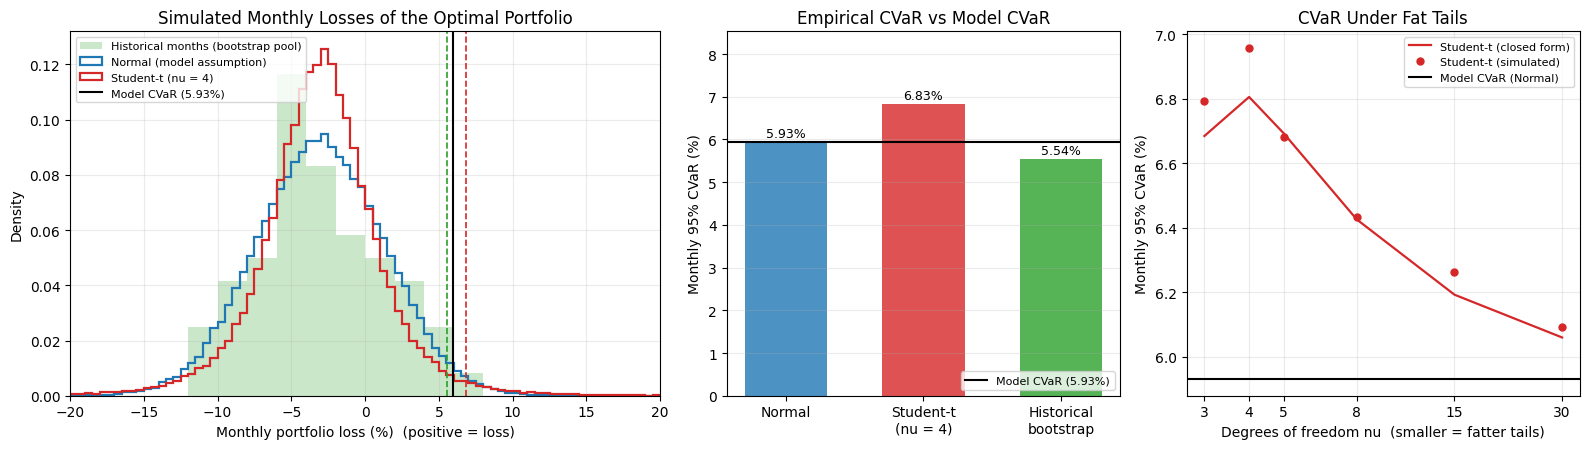

In [34]:
import matplotlib.pyplot as plt

colors = {"Normal (model assumption)": "tab:blue", f"Student-t (nu = {nu})": "tab:red", "Historical bootstrap": "tab:green"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.5, 1, 1]})

# Left: loss distributions
ax = axes[0]
bins = np.arange(-20, 20.5, 0.5)
hist_portfolio_losses = -100 * (hist_returns @ w_star)
ax.hist(hist_portfolio_losses, bins=np.arange(-20, 21, 2), density=True, color="tab:green", alpha=0.25,
        label="Historical months (bootstrap pool)")
for name in ["Normal (model assumption)", f"Student-t (nu = {nu})"]:
    ax.hist(-100 * mc_portfolio_returns[name], bins=bins, density=True, histtype="step", linewidth=1.6,
            color=colors[name], label=name)
for name, cvar in zip(mc_df["Scenario"], mc_df["Empirical CVaR 95%"]):
    ax.axvline(100 * cvar, color=colors[name], linestyle="--", linewidth=1.2)
ax.axvline(100 * model_cvar, color="black", linewidth=1.5, label=f"Model CVaR ({model_cvar:.2%})")
ax.set_xlim(-20, 20)
ax.set_xlabel("Monthly portfolio loss (%)  (positive = loss)")
ax.set_ylabel("Density")
ax.set_title("Simulated Monthly Losses of the Optimal Portfolio")
ax.legend(fontsize=8, loc="upper left")
ax.grid(alpha=0.25)

# Middle: empirical CVaR vs model CVaR
ax = axes[1]
labels = ["Normal", f"Student-t\n(nu = {nu})", "Historical\nbootstrap"]
values = 100 * mc_df["Empirical CVaR 95%"].to_numpy()
ax.bar(labels, values, color=[colors[nm] for nm in mc_df["Scenario"]], alpha=0.8, width=0.6)
ax.axhline(100 * model_cvar, color="black", linewidth=1.5, label=f"Model CVaR ({model_cvar:.2%})")
for x, v in enumerate(values):
    ax.text(x, v + 0.12, f"{v:.2f}%", ha="center", fontsize=9)
ax.set_ylim(0, values.max() * 1.25)
ax.set_ylabel("Monthly 95% CVaR (%)")
ax.set_title("Empirical CVaR vs Model CVaR")
ax.legend(loc="lower right", fontsize=8)
ax.grid(alpha=0.25, axis="y")

# Right: tail-thickness sensitivity
ax = axes[2]
ax.plot(tail_df["nu"], 100 * tail_df["Closed-form CVaR 95%"], color="tab:red", linewidth=1.6, label="Student-t (closed form)")
ax.plot(tail_df["nu"], 100 * tail_df["Empirical CVaR 95%"], "o", color="tab:red", markersize=5, label="Student-t (simulated)")
ax.axhline(100 * model_cvar, color="black", linewidth=1.5, label="Model CVaR (Normal)")
ax.set_xscale("log")
ax.set_xticks(nu_values)
ax.set_xticklabels(nu_values)
ax.minorticks_off()
ax.set_xlabel("Degrees of freedom nu  (smaller = fatter tails)")
ax.set_ylabel("Monthly 95% CVaR (%)")
ax.set_title("CVaR Under Fat Tails")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig("monte_carlo_cvar.png", dpi=200, bbox_inches="tight")
plt.show()

### Milestone 5 — What-if Analysis: What if the investor requires a higher expected return?

The model requires the portfolio's expected monthly return to be at least $b$, the historical mean monthly S&P 500 return (1.0990%). We raise $b$ step by step and re-solve the complete model at each value, recording the optimal CVaR, the standard deviation, the number of stocks held, and the largest weight. We stop at the first infeasible value: raising $b$ only shrinks the feasible set, so every higher value is infeasible too.

Two facts are known before running the code:
- as long as $b \le 3.0043\%$ (the expected return of the recommended portfolio), the recommended portfolio stays feasible and optimal, so the CVaR stays at 5.9301% and the curve is flat;
- above that level, the return constraint becomes binding: the expected return equals $b$ exactly and the CVaR can only increase.

In [35]:
# =====================================================================
# What-if: what if the investor requires a higher expected return?
# =====================================================================

# --- (a) Retrieve the minimum-return constraint of the model -------------
ret_constr = m.getConstrByName("minimum_return")

b_baseline = ret_constr.RHS          # .RHS is the right-hand side of the constraint, here b
m.Params.OutputFlag = 0              # silence Gurobi's log during the loop

# Tighter tolerances: with Gurobi's defaults, the norm constraint can be slightly
# violated, which makes the flat part of the curve jitter by a few thousandths of a point.
tight_params = {"MIPGap": 1e-7, "FeasibilityTol": 1e-9, "OptimalityTol": 1e-9, "BarQCPConvTol": 1e-9}
default_params = {p: m.getParamInfo(p)[5] for p in tight_params}   # Gurobi default values
for p, v in tight_params.items():
    m.setParam(p, v)

# --- (b) Values of b to test, in decimals ---------------------------------
# The baseline, then a grid from 1.5% to 8% in steps of 0.25 percentage point.
b_values = [b_baseline] + list(np.round(np.arange(0.015, 0.0801, 0.0025), 4))

rows = []
for b_new in b_values:
    ret_constr.RHS = b_new           # change b without rebuilding the model
    m.reset()                        # discard the previous solution, then re-solve
    m.optimize()

    # Stop at the first infeasible value: higher values are infeasible too,
    # because raising b only shrinks the feasible set.
    if m.Status in (GRB.INFEASIBLE, GRB.INF_OR_UNBD):
        print(f"Infeasible from b = {b_new:.2%}")
        break
    if m.Status != GRB.OPTIMAL:
        print(f"Not solved to optimality at b = {b_new:.2%} (status {m.Status})")
        break

    w_opt = np.asarray(w.X, dtype=float)          # optimal weights for this b
    w_opt[w_opt < 1e-8] = 0.0                     # clean solver noise
    rows.append({
        "Required return b": b_new,
        "Expected return": float(mu @ w_opt),
        "Std dev": float(np.sqrt(w_opt @ Sigma @ w_opt)),
        # CVaR recomputed from the weights (exact formula, not the solver's objective value)
        "CVaR 95%": float(-mu @ w_opt + k * np.sqrt(w_opt @ Sigma @ w_opt)),
        "Stocks held": int((w_opt > 0).sum()),
        "Largest weight": w_opt.max(),
        "Holdings": ", ".join(t for t, x in zip(tickers, w_opt) if x > 0),
    })

whatif_b = pd.DataFrame(rows)

# Marginal cost: extra CVaR (in pp) for each additional percentage point of b.
whatif_b["Extra CVaR per +1pp of b"] = (
    whatif_b["CVaR 95%"].diff() / whatif_b["Required return b"].diff()
)

print(whatif_b.drop(columns="Holdings").to_string(index=False, formatters={
    "Required return b": "{:.2%}".format, "Expected return": "{:.3%}".format,
    "Std dev": "{:.3%}".format, "CVaR 95%": "{:.3%}".format,
    "Largest weight": "{:.2%}".format, "Extra CVaR per +1pp of b": "{:.3f}".format,
}))
whatif_b.to_csv("whatif_return_hurdle.csv", index=False)

# --- (c) Restore the baseline model --------------------------------------
# IMPORTANT: any later cell reading w.X must see the recommended portfolio,
# not the portfolio of the last b tested.
ret_constr.RHS = b_baseline
for p, v in default_params.items():
    m.setParam(p, v)
m.reset()
m.optimize()
m.Params.OutputFlag = 1
print(f"\nBaseline restored: b = {ret_constr.RHS:.4%}, CVaR = {m.ObjVal:.4%}")

Infeasible from b = 5.75%
Required return b Expected return Std dev CVaR 95%  Stocks held Largest weight Extra CVaR per +1pp of b
            1.10%          3.004%  4.331%   5.930%            9         20.00%                      NaN
            1.50%          3.004%  4.331%   5.930%            9         20.00%                   -0.000
            1.75%          3.004%  4.331%   5.930%            9         20.00%                   -0.000
            2.00%          3.004%  4.331%   5.930%            9         20.00%                    0.000
            2.25%          3.005%  4.332%   5.930%            9         20.00%                    0.000
            2.50%          3.004%  4.331%   5.930%            9         20.00%                   -0.000
            2.75%          3.004%  4.331%   5.930%            9         20.00%                    0.000
            3.00%          3.004%  4.331%   5.930%            9         20.00%                    0.000
            3.25%          3.250%  4.4

In [36]:
# Holdings for each tested b (which stocks the model concentrates in as b rises)
for _, r in whatif_b.iterrows():
    print(f"b = {r['Required return b']:.2%}  ({r['Stocks held']} stocks): {r['Holdings']}")

b = 1.10%  (9 stocks): BABA, CVS, CAH, ESLT, FIX, INSM, DB, WPM, AVGO
b = 1.50%  (9 stocks): BABA, CVS, CAH, ESLT, FIX, INSM, DB, WPM, AVGO
b = 1.75%  (9 stocks): BABA, CVS, CAH, ESLT, FIX, INSM, DB, WPM, AVGO
b = 2.00%  (9 stocks): BABA, CVS, CAH, ESLT, FIX, INSM, DB, WPM, AVGO
b = 2.25%  (9 stocks): BABA, CVS, CAH, ESLT, FIX, INSM, DB, WPM, AVGO
b = 2.50%  (9 stocks): BABA, CVS, CAH, ESLT, FIX, INSM, DB, WPM, AVGO
b = 2.75%  (9 stocks): BABA, CVS, CAH, ESLT, FIX, INSM, DB, WPM, AVGO
b = 3.00%  (9 stocks): BABA, CVS, CAH, ESLT, FIX, INSM, DB, WPM, AVGO
b = 3.25%  (10 stocks): BABA, CVS, CAH, ESLT, FIX, CLS, INSM, DB, WPM, AVGO
b = 3.50%  (10 stocks): BABA, CVS, CAH, ESLT, FIX, CLS, INSM, DB, WPM, AVGO
b = 3.75%  (8 stocks): CAH, ESLT, FIX, CLS, INSM, DB, WPM, AVGO
b = 4.00%  (9 stocks): CAH, ESLT, FIX, CLS, INSM, DB, KGC, WPM, AVGO
b = 4.25%  (8 stocks): CAH, ESLT, FIX, CLS, INSM, KGC, WPM, AVGO
b = 4.50%  (8 stocks): CAH, ESLT, FIX, CLS, INSM, KGC, WPM, AVGO
b = 4.75%  (8 stocks): PL

#### Highest Feasible Return Requirement

The grid only brackets the feasibility limit. To find it exactly, we solve a copy of the model that **maximizes** the expected return $\hat\mu^{M\top} w$ under all the other constraints (full investment, 1%–20% weights, correlation exclusions), with the minimum-return constraint removed. Its optimal value is the highest $b$ for which the model is feasible.

In [37]:
m_max = m.copy()
m_max.Params.OutputFlag = 0
m_max.remove(m_max.getConstrByName("minimum_return"))
w_max_vars = [m_max.getVarByName(f"w[{i}]") for i in range(len(tickers))]
m_max.setObjective(gp.quicksum(mu[i] * w_max_vars[i] for i in range(len(tickers))), GRB.MAXIMIZE)
m_max.optimize()

b_max = m_max.ObjVal
w_bmax = np.array([v.X for v in w_max_vars])
print(f"Highest feasible required return b_max: {b_max:.4%}")
print("Portfolio at b_max:",
      ", ".join(f"{t} {x:.1%}" for t, x in zip(tickers, w_bmax) if x > 1e-6))

Highest feasible required return b_max: 5.7327%
Portfolio at b_max: CVNA 20.0%, PLTR 20.0%, FIX 20.0%, CLS 20.0%, INSM 20.0%


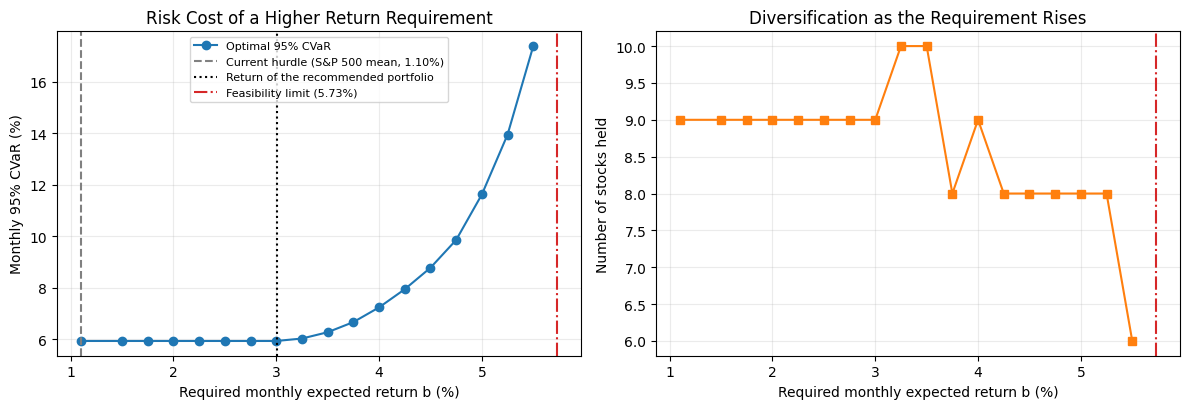

In [38]:
# --- (d) Figure ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
ax.plot(100 * whatif_b["Required return b"], 100 * whatif_b["CVaR 95%"],
        "o-", color="tab:blue", label="Optimal 95% CVaR")
ax.axvline(100 * b_baseline, color="grey", linestyle="--",
           label=f"Current hurdle (S&P 500 mean, {b_baseline:.2%})")
ax.axvline(100 * whatif_b["Expected return"].iloc[0], color="black", linestyle=":",
           label="Return of the recommended portfolio")
ax.axvline(100 * b_max, color="tab:red", linestyle="-.", label=f"Feasibility limit ({b_max:.2%})")
ax.set_xlabel("Required monthly expected return b (%)")
ax.set_ylabel("Monthly 95% CVaR (%)")
ax.set_title("Risk Cost of a Higher Return Requirement")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)

ax = axes[1]
ax.plot(100 * whatif_b["Required return b"], whatif_b["Stocks held"],
        "s-", color="tab:orange")
ax.axvline(100 * b_max, color="tab:red", linestyle="-.")
ax.set_xlabel("Required monthly expected return b (%)")
ax.set_ylabel("Number of stocks held")
ax.set_title("Diversification as the Requirement Rises")
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig("whatif_return_hurdle.png", dpi=200, bbox_inches="tight")
plt.show()